# Análisis Exploratorio del Dataset CounselChat


## 1. Carga del dataset y exploración inicial

CounselChat es una plataforma online donde terapeutas certificados responden preguntas de pacientes sobre salud mental. El dataset contiene 2.775 respuestas de terapeutas a 940 preguntas únicas, con valoraciones de la comunidad (upvotes) que uso como señal de calidad.

En esta sección analizo la estructura básica del dataset: número de respuestas por pregunta, distribución de upvotes y temas clínicos disponibles.

In [19]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

RUTA = "/content/drive/MyDrive/TFG"

# Cargo el dataset
dataset = load_dataset("nbertagnolli/counsel-chat")
df = dataset["train"].to_pandas()

print(f"Total ejemplos: {len(df)}")
print(f"Columnas: {df.columns.tolist()}")
print(f"\nPrimeras filas:")
df.head(3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Repo card metadata block was not found. Setting CardData to empty.


Total ejemplos: 2775
Columnas: ['questionID', 'questionTitle', 'questionText', 'questionLink', 'topic', 'therapistInfo', 'therapistURL', 'answerText', 'upvotes', 'views']

Primeras filas:


,questionID,questionTitle,questionText,questionLink,topic,therapistInfo,therapistURL,answerText,upvotes,views
0,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Jennifer MolinariHypnotherapist & Licensed Cou...,https://counselchat.com/therapists/jennifer-mo...,It is very common for people to have multiple ...,3,1971
1,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Jason Lynch, MS, LMHC, LCAC, ADSIndividual & C...",https://counselchat.com/therapists/jason-lynch...,"I've never heard of someone having ""too many i...",2,386
2,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Shakeeta TorresFaith Based Mental Health Couns...,https://counselchat.com/therapists/shakeeta-to...,Absolutely not. I strongly recommending worki...,2,3071


Las primeras filas muestran que una misma pregunta puede tener varias respuestas de distintos terapeutas con diferentes upvotes. Esta estructura es la base de la tarea de ranking: dado el mensaje de un paciente, ordenar las respuestas por calidad.

In [20]:
# Estadisticas basicas del dataset
print("ESTADISTICAS GENERALES")
print("=" * 40)
print(f"Total respuestas: {len(df)}")
print(f"Preguntas unicas: {df['questionID'].nunique()}")
print(f"Terapeutas unicos: {df['therapistInfo'].nunique()}")
print(f"Temas unicos: {df['topic'].nunique()}")

print(f"\nRespuestas por pregunta:")
respuestas_por_pregunta = df.groupby('questionID').size()
print(respuestas_por_pregunta.describe())

print(f"\nDistribucion de upvotes:")
print(df['upvotes'].describe())

ESTADISTICAS GENERALES
Total respuestas: 2775
Preguntas unicas: 940
Terapeutas unicos: 437
Temas unicos: 31

Respuestas por pregunta:
count    940.000000
mean       2.952128
std        6.309623
min        1.000000
25%        1.000000
50%        1.000000
75%        3.000000
max      107.000000
dtype: float64

Distribucion de upvotes:
count    2775.000000
mean        0.519640
std         1.042825
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max        12.000000
Name: upvotes, dtype: float64


El dataset presenta una distribución muy asimétrica en dos aspectos clave.

- Respecto a las respuestas por pregunta, la mediana es 1 pero la media es casi 3, con un máximo de 107. Esto indica que la mayoría de preguntas tienen pocas respuestas, pero algunas muy populares concentran muchas. Para el ranking necesitamos preguntas con al menos 2 respuestas, por lo que habrá que filtrar.

- Respecto a los upvotes, la mediana es 0 y la media es 0.52, lo que indica que la mayoría de respuestas no recibe ningún upvote. Esto es importante porque los upvotes son nuestra señal de calidad principal.

## 2. Distribución de temas clínicos

Analizo qué temas clínicos están presentes en el dataset y cuántas
preguntas y respuestas tiene cada uno.

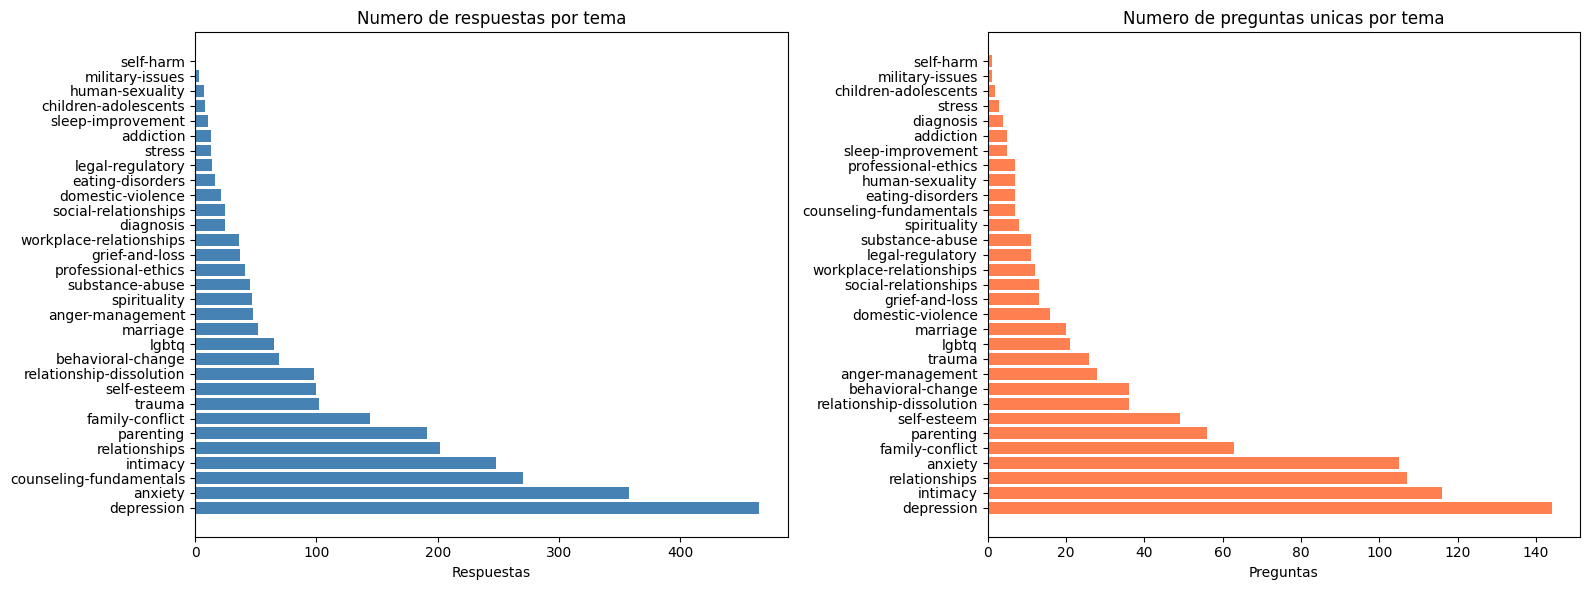

In [21]:
import os
# Distribucion de temas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Respuestas por tema
topic_respuestas = df.groupby('topic').size().sort_values(ascending=False)
axes[0].barh(topic_respuestas.index, topic_respuestas.values, color='steelblue')
axes[0].set_title('Numero de respuestas por tema')
axes[0].set_xlabel('Respuestas')

# Preguntas unicas por tema
topic_preguntas = df.groupby('topic')['questionID'].nunique().sort_values(ascending=False)
axes[1].barh(topic_preguntas.index, topic_preguntas.values, color='coral')
axes[1].set_title('Numero de preguntas unicas por tema')
axes[1].set_xlabel('Preguntas')

plt.tight_layout()
os.makedirs(f"{RUTA}/reports", exist_ok=True)
plt.savefig(f"{RUTA}/reports/distribucion_temas.png", dpi=150, bbox_inches='tight')
plt.show()


Los temas más frecuentes en el dataset son depresión, intimidad y relaciones, que concentran la mayor parte de las preguntas y respuestas. En el extremo opuesto, temas como self-harm o military-issues tienen muy poca representación.

Esta distribución desequilibrada es relevante para el TFG porque los sistemas de ranking pueden funcionar mejor en temas con más datos. En el análisis de resultados tendré en cuenta si el rendimiento varía según el tema clínico.

## 3. Distribución de upvotes

Los upvotes son la señal de calidad principal del dataset. Analizo su
distribución para entender cómo de fiable es esta señal para el ranking.

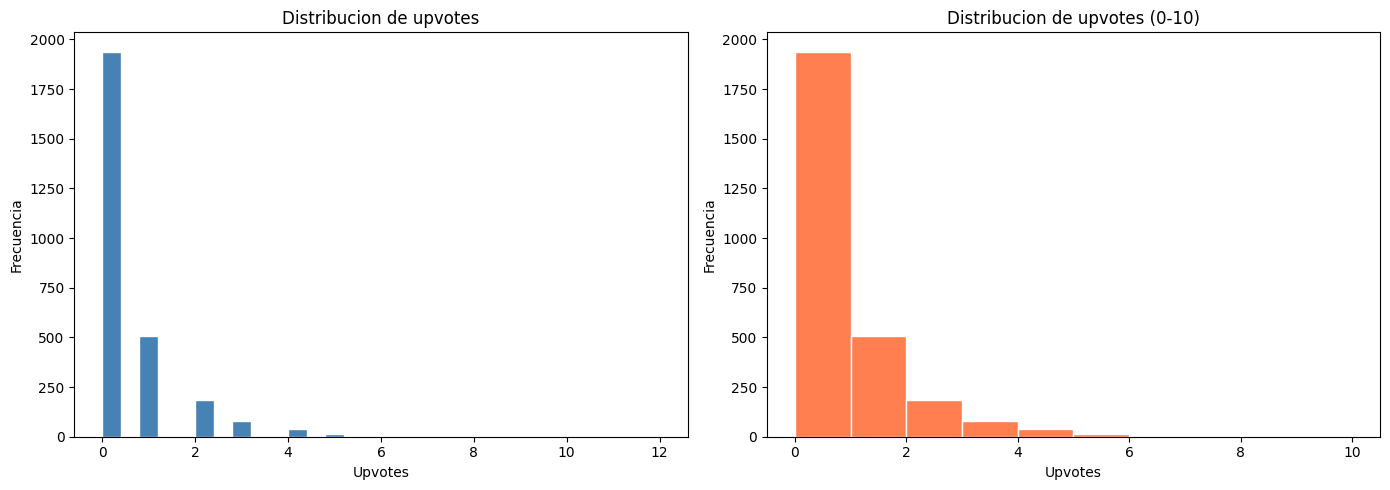

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribucion general de upvotes
axes[0].hist(df['upvotes'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Distribucion de upvotes')
axes[0].set_xlabel('Upvotes')
axes[0].set_ylabel('Frecuencia')

# Zoom en upvotes bajos (0-10)
df_zoom = df[df['upvotes'] <= 10]
axes[1].hist(df_zoom['upvotes'], bins=10, color='coral', edgecolor='white')
axes[1].set_title('Distribucion de upvotes (0-10)')
axes[1].set_xlabel('Upvotes')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
os.makedirs(f"{RUTA}/reports", exist_ok=True)
plt.savefig(f"{RUTA}/reports/distribucion_upvotes.png", dpi=150, bbox_inches='tight')
plt.show()

La distribución de upvotes es muy asimétrica: la gran mayoría de respuestas recibe 0 o 1 upvote, y muy pocas alcanzan valores altos. Concretamente, más del 70% de las respuestas tiene 0 upvotes.

Esto tiene implicaciones importantes para el TFG. Por un lado, el dataset es ruidoso: muchas respuestas de calidad similar tienen el mismo número de upvotes (cero), lo que hace difícil distinguirlas. Por otro lado, cuando una
respuesta sí recibe upvotes, es una señal más fiable de que es claramente
mejor que las demás.

Por ello, en la construcción del dataset de ranking filtraré las preguntas que tengan al menos dos respuestas con distinto número de upvotes, para
garantizar que haya una señal de preferencia clara.

## 4. Análisis de longitud de las respuestas

Analizo la longitud de las respuestas de los terapeutas para entender
si existe relación entre la longitud y la calidad percibida (upvotes).
Esta información es relevante porque uno de los baselines que implementaré
selecciona la respuesta más larga.

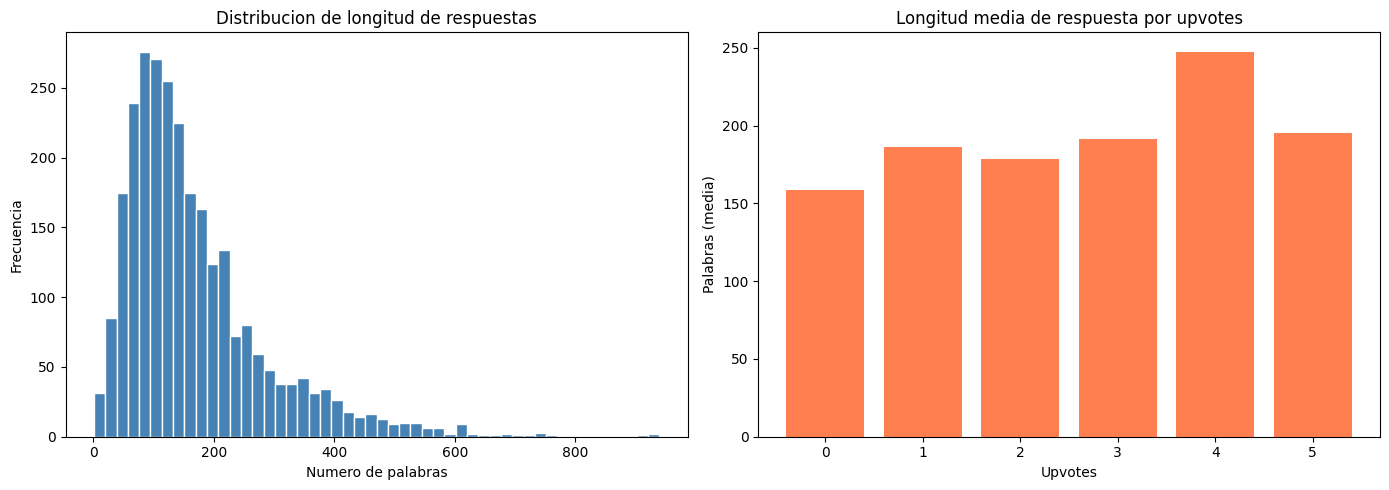

Longitud media: 168.0 palabras
Longitud mediana: 136.0 palabras


In [23]:
# Añado columna de longitud en palabras
df['longitud_respuesta'] = df['answerText'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribucion de longitud
axes[0].hist(df['longitud_respuesta'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribucion de longitud de respuestas')
axes[0].set_xlabel('Numero de palabras')
axes[0].set_ylabel('Frecuencia')

# Longitud media por numero de upvotes (hasta 5)
df_upvotes = df[df['upvotes'] <= 5].copy()
longitud_por_upvotes = df_upvotes.groupby('upvotes')['longitud_respuesta'].mean()
axes[1].bar(longitud_por_upvotes.index, longitud_por_upvotes.values, color='coral')
axes[1].set_title('Longitud media de respuesta por upvotes')
axes[1].set_xlabel('Upvotes')
axes[1].set_ylabel('Palabras (media)')

plt.tight_layout()
plt.savefig(f"{RUTA}/reports/longitud_respuestas.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"Longitud media: {df['longitud_respuesta'].mean():.1f} palabras")
print(f"Longitud mediana: {df['longitud_respuesta'].median():.1f} palabras")

La longitud media de las respuestas es de 168 palabras, con una mediana de 136 palabras. La distribución es asimétrica hacia la derecha, con algunas respuestas muy largas que elevan la media.

El gráfico de la derecha muestra una tendencia interesante: las respuestas con más upvotes tienden a ser más largas, especialmente las que reciben 4
upvotes. Esto sugiere que la longitud puede ser una señal útil de calidad,
aunque no determinante, ya que las respuestas con 5 upvotes son más cortas
que las de 4.

Esta observación justifica incluir la longitud como uno de los baselines,
aunque los resultados indican que por sí sola no es suficiente para predecir
la calidad de forma fiable.

## 5. Análisis de la estructura para ranking

Para la tarea de ranking necesito preguntas con al menos 2 respuestas y
con diferente número de upvotes, para que haya una señal de preferencia
clara. En esta sección analizo cuántas preguntas cumplen estos requisitos.

ANALISIS DE VIABILIDAD PARA RANKING
--------------------------------------------------
Preguntas con 1 sola respuesta:          480
Preguntas con 2 o mas respuestas:        460
Preguntas con upvotes distintos:         257

Porcentaje viable para ranking:          27.3%


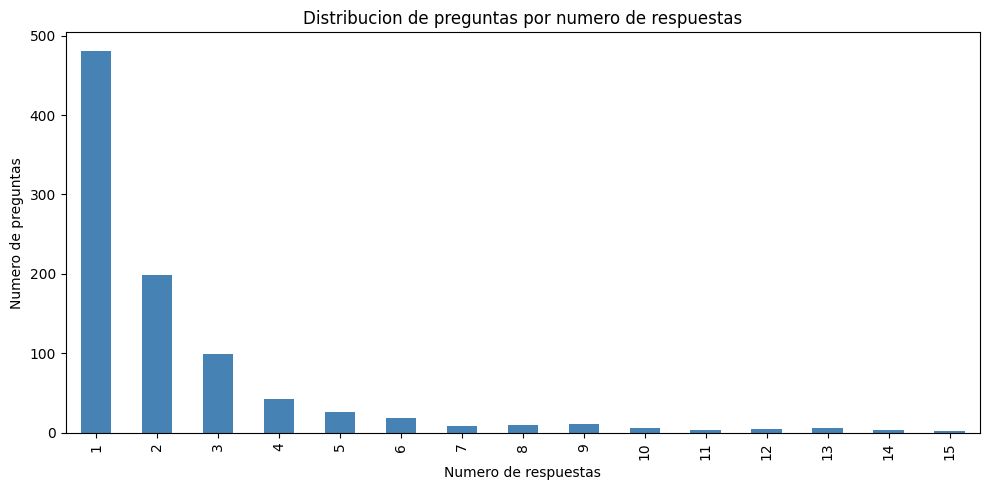

In [24]:
# Analizo cuantas preguntas tienen al menos 2 respuestas
grupos = df.groupby('questionID')

preguntas_1_resp = sum(1 for _, g in grupos if len(g) == 1)
preguntas_2_resp = sum(1 for _, g in grupos if len(g) >= 2)
preguntas_upvotes_distintos = sum(1 for _, g in grupos if len(g) >= 2 and g['upvotes'].nunique() > 1)

print("ANALISIS DE VIABILIDAD PARA RANKING")
print("-" * 50)
print(f"Preguntas con 1 sola respuesta:          {preguntas_1_resp}")
print(f"Preguntas con 2 o mas respuestas:        {preguntas_2_resp}")
print(f"Preguntas con upvotes distintos:         {preguntas_upvotes_distintos}")
print(f"\nPorcentaje viable para ranking:          {preguntas_upvotes_distintos/len(grupos)*100:.1f}%")

# Distribucion de preguntas por numero de respuestas
n_respuestas = df.groupby('questionID').size()
fig, ax = plt.subplots(figsize=(10, 5))
n_respuestas.value_counts().sort_index().head(15).plot(kind='bar', ax=ax, color='steelblue') # Devuelve un Series dode el índice son los números de respuesta y los avlores cuántas prgeuntas tienen ese número
# pandas los hace automático: El índice del Series va al eje X y los valores del Series van al eje Y
ax.set_title('Distribucion de preguntas por numero de respuestas')
ax.set_xlabel('Numero de respuestas')
ax.set_ylabel('Numero de preguntas')
plt.tight_layout()
plt.savefig(f"{RUTA}/reports/estructura_ranking.png", dpi=150, bbox_inches='tight')
plt.show()

De las 940 preguntas del dataset, 480 tienen una sola respuesta y por tanto no son útiles para la tarea de ranking. Las 460 restantes tienen 2 o más respuestas, pero solo 257 (el 27.3% del total) tienen respuestas con upvotes distintos, es decir, con una señal de preferencia clara.

El gráfico confirma que la mayoría de preguntas tienen muy pocas respuestas, siendo 1 el valor más frecuente con diferencia.

Este análisis determina el tamaño real del dataset de ranking: trabajaré con 257 preguntas que tienen al menos 2 respuestas con upvotes distintos. Este subconjunto será la base de todos los experimentos del TFG.

## 6. Construcción del dataset de ranking

A partir del análisis anterior, construyo el dataset final filtrando las preguntas con al menos 2 respuestas y upvotes distintos. Este será el dataset base para todos los experimentos del TFG.

In [33]:
# Construyo el dataset de ranking
dataset_ranking = []

for question_id, grupo in df.groupby('questionID'):
    if len(grupo) >= 2 and grupo['upvotes'].nunique() > 1:
        grupo_ordenado = grupo.sort_values('upvotes', ascending=False)
        dataset_ranking.append({
            'questionID': question_id,
            'questionText': grupo_ordenado.iloc[0]['questionText'],
            'topic': grupo_ordenado.iloc[0]['topic'],
            'n_respuestas': len(grupo),
            'respuestas': grupo_ordenado['answerText'].tolist(),
            'upvotes': grupo_ordenado['upvotes'].tolist(),
            'mejor_respuesta': grupo_ordenado.iloc[0]['answerText'],
            'mejor_upvotes': grupo_ordenado.iloc[0]['upvotes']
        })

df_ranking = pd.DataFrame(dataset_ranking)

print("DATASET DE RANKING")
print("-" * 50)
print(f"Total preguntas: {len(df_ranking)}")
print(f"Media de respuestas por pregunta: {df_ranking['n_respuestas'].mean():.1f}")
print(f"Media de upvotes de la mejor respuesta: {df_ranking['mejor_upvotes'].mean():.1f}")
print(f"\nDistribucion por tema:")
print(df_ranking['topic'].value_counts().head(10))

# Guardo el dataset
df_ranking.to_csv(f"{RUTA}/data/dataset_ranking.csv", index=False)
print("\nDataset guardado en data/dataset_ranking.csv")

DATASET DE RANKING
--------------------------------------------------
Total preguntas: 257
Media de respuestas por pregunta: 6.6
Media de upvotes de la mejor respuesta: 2.3

Distribucion por tema:
topic
depression                  39
anxiety                     29
relationships               25
intimacy                    24
parenting                   18
family-conflict             15
self-esteem                 14
trauma                      10
lgbtq                       10
relationship-dissolution     9
Name: count, dtype: int64

Dataset guardado en data/dataset_ranking.csv


El dataset final de ranking contiene 257 preguntas con una media de 6.6 respuestas por pregunta y una media de 2.3 upvotes para la mejor respuesta.

Los temas más representados son depresión (39), ansiedad (29) y relaciones (25), lo que refleja las preocupaciones más frecuentes en plataformas de apoyo en salud mental.

Este dataset queda guardado en data/dataset_ranking.csv y será la base
de todos los experimentos del TFG.

## 7. División train/val/test

Divido el dataset en tres subconjuntos para poder entrenar, ajustar y
evaluar los sistemas de forma rigurosa, evitando fuga de información.
La división se hace a nivel de pregunta, no de respuesta, para garantizar
que el mismo questionID no aparezca en más de un subconjunto.

In [34]:
from sklearn.model_selection import train_test_split

# Division train/val/test (70/15/15)
train, temp = train_test_split(df_ranking, test_size=0.3, random_state=2411)
val, test = train_test_split(temp, test_size=0.5, random_state=2411)

print("DIVISION TRAIN/VAL/TEST")
print("-" * 40)
print(f"Train: {len(train)} preguntas ({len(train)/len(df_ranking)*100:.1f}%)")
print(f"Val:   {len(val)} preguntas ({len(val)/len(df_ranking)*100:.1f}%)")
print(f"Test:  {len(test)} preguntas ({len(test)/len(df_ranking)*100:.1f}%)")

# Guardo las divisiones
train.to_csv(f"{RUTA}/data/train.csv", index=False)
val.to_csv(f"{RUTA}/data/val.csv", index=False)
test.to_csv(f"{RUTA}/data/test.csv", index=False)
print("\nDivisiones guardadas en data/")

DIVISION TRAIN/VAL/TEST
----------------------------------------
Train: 179 preguntas (69.6%)
Val:   39 preguntas (15.2%)
Test:  39 preguntas (15.2%)

Divisiones guardadas en data/


La división queda en 179 preguntas para entrenamiento, 39 para validación y 39 para test. La división se ha realizado a nivel de pregunta con semilla aleatoria fija (random_state=2411) para garantizar la reproducibilidad.

El conjunto de test no se utilizará hasta la evaluación final de los sistemas, para evitar sobreajuste en la selección de hiperparámetros y decisiones de diseño.

## 8. Baselines

Implemento cuatro sistemas de ranking de complejidad creciente que sirven
como punto de comparación para métodos más avanzados. Todos se evalúan
sobre el conjunto de validación (val) usando Precision@1 y MRR.

- **Baseline 1:** selección aleatoria
- **Baseline 2:** respuesta más larga
- **Baseline 3:** coincidencia léxica con la pregunta del paciente
- **Baseline 4:** TF-IDF

In [42]:
import random
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import ast

# Cargo el conjunto de validacion
val = pd.read_csv(f"{RUTA}/data/val.csv")

# Convierto las columnas de listas
val['respuestas'] = val['respuestas'].apply(ast.literal_eval)
val['upvotes'] = val['upvotes'].apply(ast.literal_eval)

def precision_at_1(predicciones, upvotes_lista):
    """Calcula Precision@1: 1 si la primera prediccion es la mejor respuesta"""
    mejor_idx = upvotes_lista.index(max(upvotes_lista))
    return 1 if predicciones[0] == mejor_idx else 0

def mrr(predicciones, upvotes_lista):
    """Calcula MRR: 1/posicion de la mejor respuesta en el ranking"""
    mejor_idx = upvotes_lista.index(max(upvotes_lista))
    posicion = predicciones.index(mejor_idx) + 1
    return 1 / posicion

def evaluar(nombre, predicciones_fn):
    p1_scores = []
    mrr_scores = []
    for _, fila in val.iterrows():
        respuestas = fila['respuestas']
        upvotes = fila['upvotes']
        ranking = predicciones_fn(fila['questionText'], respuestas)
        p1_scores.append(precision_at_1(ranking, upvotes))
        mrr_scores.append(mrr(ranking, upvotes))
    print(f"{nombre}:")
    print(f"  Precision@1: {sum(p1_scores)/len(p1_scores):.3f}")
    print(f"  MRR:         {sum(mrr_scores)/len(mrr_scores):.3f}\n")

# BASELINE 1: Aleatorio
def baseline_aleatorio(pregunta, respuestas):
    indices = list(range(len(respuestas)))
    random.shuffle(indices)
    return indices

# BASELINE 2: Respuesta mas larga
def baseline_mas_larga(pregunta, respuestas):
    longitudes = [len(str(r).split()) if r is not None else 0 for r in respuestas]
    return sorted(range(len(respuestas)), key=lambda i: longitudes[i], reverse=True)

# BASELINE 3: Coincidencia lexica
def baseline_lexica(pregunta, respuestas):
    palabras_pregunta = set(str(pregunta).lower().split())
    coincidencias = [len(palabras_pregunta & set(str(r).lower().split())) if r is not None else 0 for r in respuestas]
    return sorted(range(len(respuestas)), key=lambda i: coincidencias[i], reverse=True)

# BASELINE 4: TF-IDF
def baseline_tfidf(pregunta, respuestas):
    respuestas_limpias = [str(r) if r is not None and str(r) != 'nan' else '' for r in respuestas]
    textos = [str(pregunta)] + respuestas_limpias
    tfidf = TfidfVectorizer().fit_transform(textos)
    similitudes = cosine_similarity(tfidf[0:1], tfidf[1:])[0]
    return sorted(range(len(respuestas)), key=lambda i: similitudes[i], reverse=True)

print("RESULTADOS DE BASELINES EN VAL")
print("-" * 40)
evaluar("Baseline aleatorio", baseline_aleatorio)
evaluar("Baseline respuesta mas larga", baseline_mas_larga)
evaluar("Baseline coincidencia lexica", baseline_lexica)
evaluar("Baseline TF-IDF", baseline_tfidf)

RESULTADOS DE BASELINES EN VAL
----------------------------------------
Baseline aleatorio:
  Precision@1: 0.410
  MRR:         0.566

Baseline respuesta mas larga:
  Precision@1: 0.308
  MRR:         0.511

Baseline coincidencia lexica:
  Precision@1: 0.487
  MRR:         0.638

Baseline TF-IDF:
  Precision@1: 0.410
  MRR:         0.608



Los resultados muestran diferencias interesantes entre los cuatro baselines.

- El baseline aleatorio obtiene una Precision@1 de 0.410 y un MRR de 0.566, que sirve como referencia mínima que cualquier sistema útil debe superar.

- La respuesta más larga obtiene los peores resultados (Precision@1: 0.308), lo que indica que la longitud por sí sola no es un buen predictor de calidad.

- La coincidencia léxica es el mejor baseline con una Precision@1 de 0.487 y un MRR de 0.638, lo que sugiere que las respuestas más relevantes comparten vocabulario con la pregunta del paciente.

- TF-IDF obtiene resultados similares al aleatorio (Precision@1: 0.410), lo que sugiere que la similitud semántica superficial no es suficiente para distinguir respuestas de calidad en este dominio.

In [43]:
# Guardo los resultados en reports/
resultados = pd.DataFrame({
    "sistema": [
        "Baseline aleatorio",
        "Baseline respuesta mas larga",
        "Baseline coincidencia lexica",
        "Baseline TF-IDF"
    ],
    "precision_at_1": [0.410, 0.308, 0.487, 0.410],
    "mrr": [0.566, 0.511, 0.638, 0.608],
    "conjunto": ["val"] * 4
})

resultados.to_csv(f"{RUTA}/reports/resultados_baselines.csv", index=False)
print("Resultados guardados en reports/resultados_baselines.csv")
print(resultados.to_string(index=False))

Resultados guardados en reports/resultados_baselines.csv
                     sistema  precision_at_1   mrr conjunto
          Baseline aleatorio           0.410 0.566      val
Baseline respuesta mas larga           0.308 0.511      val
Baseline coincidencia lexica           0.487 0.638      val
             Baseline TF-IDF           0.410 0.608      val
